# Unsupervised Learning and Dimensionality Reduction Case Study (Wine Chemistry)

**Subject:** Machine Learning (METCE11504) &nbsp;|&nbsp; **Activity:** ALA 2  
**Student:** ____________________ &nbsp; **Enrollment No.:** ____________

## 1. Objective
Apply **unsupervised learning** (K-Means, Kernel K-Means) and **dimensionality reduction** (PCA, Kernel PCA) to a given dataset, analyse the clustering behaviour, visualise the results and interpret the reduced feature space — i.e. understand the structure of data **without using labels**.

## 2. Dataset
*Wine* dataset (UCI; included in scikit-learn): **178 wines, 13 chemical measurements** (alcohol, malic acid, ash, alkalinity, magnesium, phenols, flavanoids, colour intensity, hue, proline, ...) from **three grape cultivars** grown in the same region of Italy.  
The cultivar label is **hidden during learning** and used only afterwards to *check* how well the discovered clusters match reality (external validation).

## 3. Algorithm selection (explanation)
| Technique | Why it is used here |
|---|---|
| **K-Means** | Simple, fast partitioning method; the natural first choice for compact, roughly spherical clusters. Needs the number of clusters k and **scaled** features. |
| **Kernel K-Means** | K-Means in an implicit high-dimensional feature space (RBF kernel); can find non-linearly separable clusters. Implemented from scratch. |
| **PCA** | Linear projection onto the directions of maximum variance; removes redundancy between correlated chemical measurements and allows 2-D visualisation. |
| **Kernel PCA (RBF)** | Non-linear extension of PCA; checks whether a non-linear projection separates the groups better. |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, KernelPCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.metrics.pairwise import rbf_kernel
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RS = 42

## 4. Data exploration and preprocessing

In [2]:
wine = load_wine(as_frame=True)
X = wine.data; y_true = wine.target            # y_true is NOT used for learning
print("Samples:", X.shape[0], "| Features:", X.shape[1], "| Missing values:", int(X.isna().sum().sum()))
print("True cultivar sizes (for checking only):", y_true.value_counts().sort_index().to_dict())
X.describe().loc[["mean", "std", "min", "max"]].round(2).T

Samples: 178 | Features: 13 | Missing values: 0
True cultivar sizes (for checking only): {0: 59, 1: 71, 2: 48}


                                mean     std     min      max
alcohol                        13.00    0.81   11.03    14.83
malic_acid                      2.34    1.12    0.74     5.80
ash                             2.37    0.27    1.36     3.23
alcalinity_of_ash              19.49    3.34   10.60    30.00
magnesium                      99.74   14.28   70.00   162.00
total_phenols                   2.30    0.63    0.98     3.88
flavanoids                      2.03    1.00    0.34     5.08
nonflavanoid_phenols            0.36    0.12    0.13     0.66
proanthocyanins                 1.59    0.57    0.41     3.58
color_intensity                 5.06    2.32    1.28    13.00
hue                             0.96    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27     4.00
proline                       746.89  314.91  278.00  1680.00

In [3]:
# The features are on very different scales (proline in hundreds/thousands, hue around 1) -> distance-based methods need standardisation
Xs = StandardScaler().fit_transform(X)
print("After standardisation: mean ~", Xs.mean().round(6), " sd ~", Xs.std().round(3))
# How much does scaling matter? Compare K-Means on raw and scaled data (ARI against the hidden cultivar, 1 = perfect)
raw = KMeans(3, n_init=10, random_state=RS).fit(X.values)
scaled = KMeans(3, n_init=10, random_state=RS).fit(Xs)
print("Adjusted Rand Index, raw data   :", round(adjusted_rand_score(y_true, raw.labels_), 3))
print("Adjusted Rand Index, scaled data:", round(adjusted_rand_score(y_true, scaled.labels_), 3))

After standardisation: mean ~ 0.0  sd ~ 1.0
Adjusted Rand Index, raw data   : 0.371
Adjusted Rand Index, scaled data: 0.897


## 5. K-Means: choosing the number of clusters

In [4]:
ks = range(2, 9)
inertia, sil, dbi, chi = [], [], [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(Xs)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_))
    dbi.append(davies_bouldin_score(Xs, km.labels_)); chi.append(calinski_harabasz_score(Xs, km.labels_))
sel = pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3), "davies_bouldin": np.round(dbi, 3), "calinski_harabasz": np.round(chi, 1)}).set_index("k")
sel

   inertia  silhouette  davies_bouldin  calinski_harabasz
k                                                        
2   1658.8       0.259           1.526               69.5
3   1277.9       0.285           1.389               70.9
4   1175.4       0.260           1.797               56.2
5   1109.5       0.202           1.808               47.0
6   1046.0       0.237           1.554               41.7
7    981.6       0.204           1.661               38.7
8    935.2       0.157           1.741               35.8

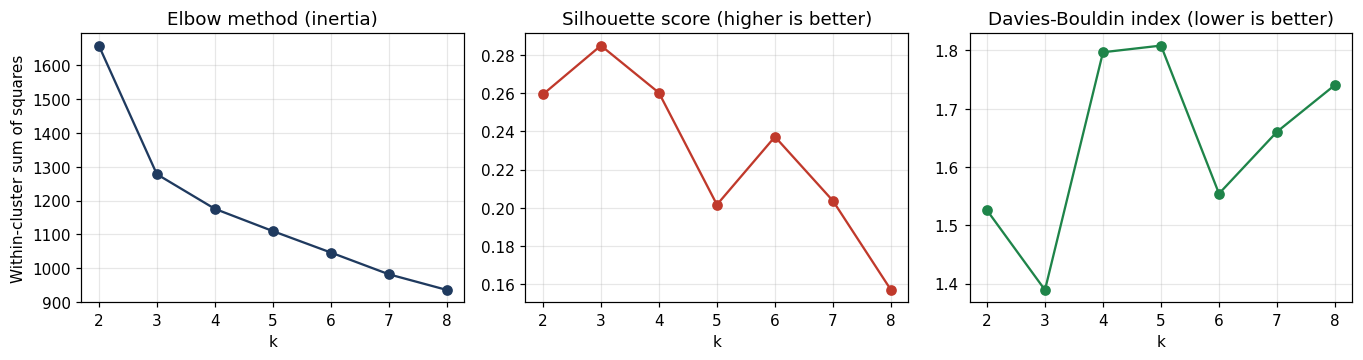

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(list(ks), inertia, "o-", color="#1F3A5F"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Within-cluster sum of squares")
ax[1].plot(list(ks), sil, "o-", color="#C0392B"); ax[1].set_title("Silhouette score (higher is better)"); ax[1].set_xlabel("k")
ax[2].plot(list(ks), dbi, "o-", color="#1E8449"); ax[2].set_title("Davies-Bouldin index (lower is better)"); ax[2].set_xlabel("k")
for a in ax: a.grid(alpha=.3)
plt.tight_layout()

In [6]:
K = 3
km = KMeans(K, n_init=20, random_state=RS).fit(Xs)
labels_km = km.labels_
print("K-Means with k =", K)
print("Cluster sizes:", np.bincount(labels_km).tolist())
print(f"Silhouette = {silhouette_score(Xs, labels_km):.3f} | Davies-Bouldin = {davies_bouldin_score(Xs, labels_km):.3f} | Calinski-Harabasz = {calinski_harabasz_score(Xs, labels_km):.1f}")
print(f"External check vs hidden cultivar: ARI = {adjusted_rand_score(y_true, labels_km):.3f} | NMI = {normalized_mutual_info_score(y_true, labels_km):.3f}")
print()
print("Contingency table (rows = K-Means cluster, columns = true cultivar):")
pd.crosstab(pd.Series(labels_km, name="cluster"), pd.Series(y_true.values, name="cultivar"))

K-Means with k = 3
Cluster sizes: [65, 51, 62]
Silhouette = 0.285 | Davies-Bouldin = 1.389 | Calinski-Harabasz = 70.9
External check vs hidden cultivar: ARI = 0.897 | NMI = 0.876

Contingency table (rows = K-Means cluster, columns = true cultivar):


cultivar   0   1   2
cluster             
0          0  65   0
1          0   3  48
2         59   3   0

In [7]:
# Cluster profiles: centroids converted back to original units
prof = pd.DataFrame(StandardScaler().fit(X).inverse_transform(km.cluster_centers_), columns=X.columns).round(2)
prof.index.name = "cluster"
prof[["alcohol", "flavanoids", "color_intensity", "proline", "hue", "total_phenols"]]

         alcohol  flavanoids  color_intensity  proline   hue  total_phenols
cluster                                                                    
0          12.25        2.05             2.97   510.17  1.06           2.25
1          13.13        0.82             7.23   619.06  0.69           1.68
2          13.68        3.00             5.45  1100.23  1.07           2.85

In [8]:
# Stability: do different random initialisations give the same partition?
aris = [adjusted_rand_score(labels_km, KMeans(K, n_init=1, random_state=s).fit(Xs).labels_) for s in range(20)]
print("Agreement (ARI) of 20 single-initialisation runs with the best solution: min %.3f, mean %.3f" % (min(aris), np.mean(aris)))

Agreement (ARI) of 20 single-initialisation runs with the best solution: min 0.882, mean 0.970


## 6. Dimensionality reduction with PCA

Explained variance ratio of the first 6 components: [0.362 0.192 0.111 0.071 0.066 0.049]
Cumulative: [0.362 0.554 0.665 0.736 0.802 0.851]
Components needed for 80% / 90% of the variance: 5 / 8


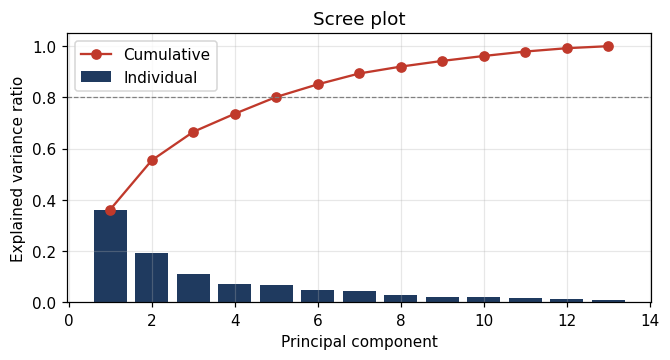

In [9]:
pca = PCA().fit(Xs)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
print("Explained variance ratio of the first 6 components:", np.round(evr[:6], 3))
print("Cumulative:", np.round(cum[:6], 3))
print("Components needed for 80%% / 90%% of the variance: %d / %d" % (np.argmax(cum >= .80) + 1, np.argmax(cum >= .90) + 1))
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.bar(range(1, 14), evr, color="#1F3A5F", label="Individual"); ax.plot(range(1, 14), cum, "o-", color="#C0392B", label="Cumulative")
ax.axhline(.8, ls="--", c="grey", lw=.8); ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance ratio"); ax.set_title("Scree plot"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()

In [10]:
# Interpretation of the reduced space: loadings = contribution of each original feature to a component
load = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"]).round(3)
print("Strongest loadings on PC1:"); print(load.PC1.sort_values(key=abs, ascending=False).head(5).to_string())
print(); print("Strongest loadings on PC2:"); print(load.PC2.sort_values(key=abs, ascending=False).head(5).to_string())

Strongest loadings on PC1:
flavanoids                      0.423
total_phenols                   0.395
od280/od315_of_diluted_wines    0.376
proanthocyanins                 0.313
nonflavanoid_phenols           -0.299

Strongest loadings on PC2:
color_intensity    0.530
alcohol            0.484
proline            0.365
ash                0.316
magnesium          0.300


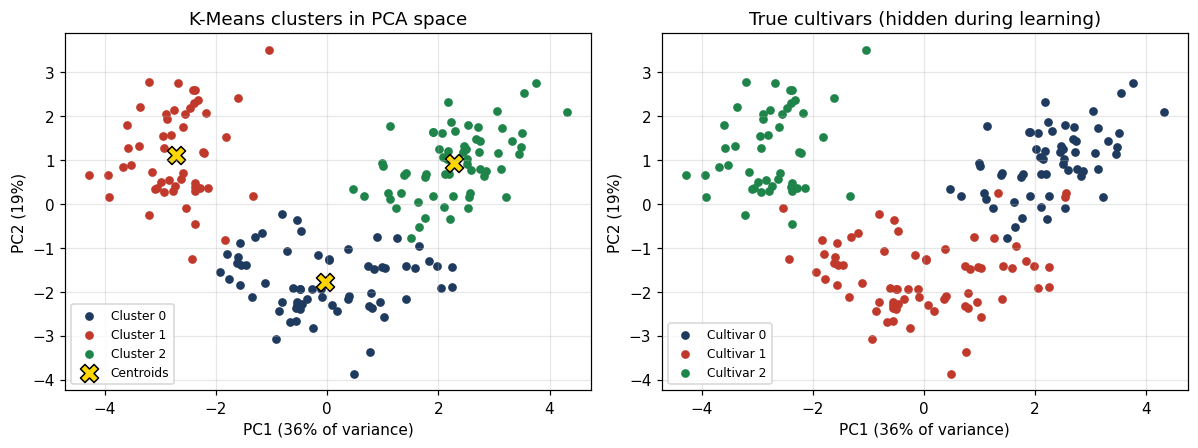

In [11]:
Z = pca.transform(Xs)[:, :2]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cols = ["#1F3A5F", "#C0392B", "#1E8449"]
for c in range(3):
    ax[0].scatter(Z[labels_km == c, 0], Z[labels_km == c, 1], s=22, color=cols[c], label=f"Cluster {c}")
    ax[1].scatter(Z[y_true.values == c, 0], Z[y_true.values == c, 1], s=22, color=cols[c], label=f"Cultivar {c}")
cen = pca.transform(km.cluster_centers_)[:, :2]; ax[0].scatter(cen[:, 0], cen[:, 1], marker="X", s=140, c="gold", edgecolor="k", label="Centroids")
ax[0].set_title("K-Means clusters in PCA space"); ax[1].set_title("True cultivars (hidden during learning)")
for a in ax: a.set_xlabel(f"PC1 ({evr[0]:.0%} of variance)"); a.set_ylabel(f"PC2 ({evr[1]:.0%})"); a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout()

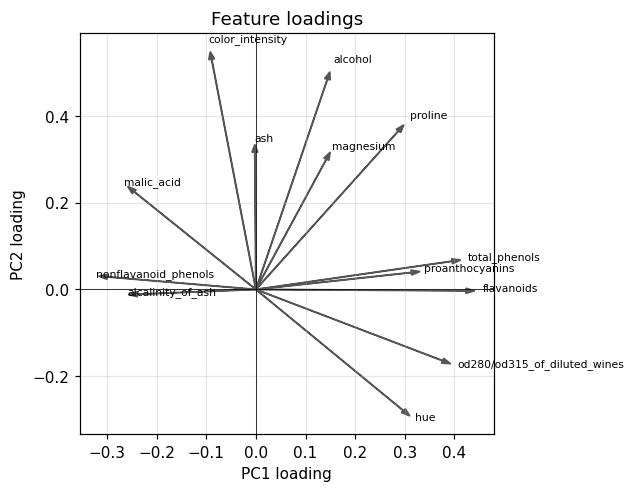

In [12]:
# Biplot-style view: original features as arrows in the PC1-PC2 plane
fig, ax = plt.subplots(figsize=(5.8, 4.6))
for f in X.columns:
    ax.arrow(0, 0, load.loc[f, "PC1"], load.loc[f, "PC2"], head_width=.012, color="#555")
    ax.text(load.loc[f, "PC1"] * 1.08, load.loc[f, "PC2"] * 1.08, f, fontsize=7)
ax.axhline(0, c="k", lw=.5); ax.axvline(0, c="k", lw=.5); ax.set_xlabel("PC1 loading"); ax.set_ylabel("PC2 loading"); ax.set_title("Feature loadings"); ax.grid(alpha=.3)
plt.tight_layout()

In [13]:
# Does clustering in the reduced space work as well? (K-Means on the first 2 and first 5 components)
rows = []
for d in (2, 3, 5, 13):
    Zd = PCA(d).fit_transform(Xs)
    lab = KMeans(3, n_init=20, random_state=RS).fit_predict(Zd)
    rows.append([d, f"{PCA(d).fit(Xs).explained_variance_ratio_.sum():.1%}", round(silhouette_score(Zd, lab), 3), round(adjusted_rand_score(y_true, lab), 3)])
pd.DataFrame(rows, columns=["components", "variance_kept", "silhouette", "ARI_vs_cultivar"]).set_index("components")

           variance_kept  silhouette  ARI_vs_cultivar
components                                           
2                  55.4%       0.561            0.895
3                  66.5%       0.453            0.880
5                  80.2%       0.369            0.897
13                100.0%       0.285            0.897

## 7. Kernel methods: Kernel PCA and Kernel K-Means

In [14]:
def kernel_kmeans(Kmat, k, n_init=10, max_iter=100, seed=0):
    """Kernel K-Means: distance of point i to cluster C in feature space
       d(i,C) = K_ii - 2/|C| * sum_{l in C} K_il + 1/|C|^2 * sum_{l,m in C} K_lm"""
    rng = np.random.default_rng(seed); n = len(Kmat); best = (np.inf, None)
    for _ in range(n_init):
        lab = rng.integers(0, k, n)
        for _ in range(max_iter):
            Zm = np.eye(k)[lab]                                   # one-hot membership matrix (n x k)
            size = Zm.sum(0) + 1e-12
            term2 = (Kmat @ Zm) / size                            # average similarity of each point to each cluster
            term3 = np.einsum("ik,ik->k", Zm, Kmat @ Zm) / size ** 2
            dist = np.diag(Kmat)[:, None] - 2 * term2 + term3[None, :]
            new = dist.argmin(1)
            if np.array_equal(new, lab): break
            lab = new
        obj = dist[np.arange(n), lab].sum()
        if obj < best[0]: best = (obj, lab.copy())
    return best[1]

rows = []
for gamma in (0.002, 0.005, 0.01, 0.02, 0.05, 0.1):
    Kmat = rbf_kernel(Xs, gamma=gamma)
    lab = kernel_kmeans(Kmat, 3, seed=1)
    rows.append([gamma, np.bincount(lab, minlength=3).tolist(), round(adjusted_rand_score(y_true, lab), 3), round(normalized_mutual_info_score(y_true, lab), 3)])
kk = pd.DataFrame(rows, columns=["rbf_gamma", "cluster_sizes", "ARI_vs_cultivar", "NMI_vs_cultivar"]).set_index("rbf_gamma")
kk

          cluster_sizes  ARI_vs_cultivar  NMI_vs_cultivar
rbf_gamma                                                
0.002      [62, 65, 51]            0.897            0.876
0.005      [62, 65, 51]            0.897            0.876
0.010      [51, 61, 66]            0.915            0.893
0.020      [61, 66, 51]            0.915            0.893
0.050      [69, 58, 51]            0.933            0.912
0.100      [58, 50, 70]            0.949            0.928

In [15]:
kpca_rows, kp = [], {}
for gamma in (0.005, 0.01, 0.02, 0.05):
    Zk = KernelPCA(2, kernel="rbf", gamma=gamma).fit_transform(Xs)
    lab = KMeans(3, n_init=20, random_state=RS).fit_predict(Zk)
    kp[gamma] = Zk
    kpca_rows.append([gamma, round(silhouette_score(Zk, lab), 3), round(adjusted_rand_score(y_true, lab), 3)])
kpca = pd.DataFrame(kpca_rows, columns=["rbf_gamma", "silhouette", "ARI_vs_cultivar"]).set_index("rbf_gamma")
kpca

           silhouette  ARI_vs_cultivar
rbf_gamma                             
0.005           0.572            0.912
0.010           0.582            0.912
0.020           0.596            0.913
0.050           0.617            0.931

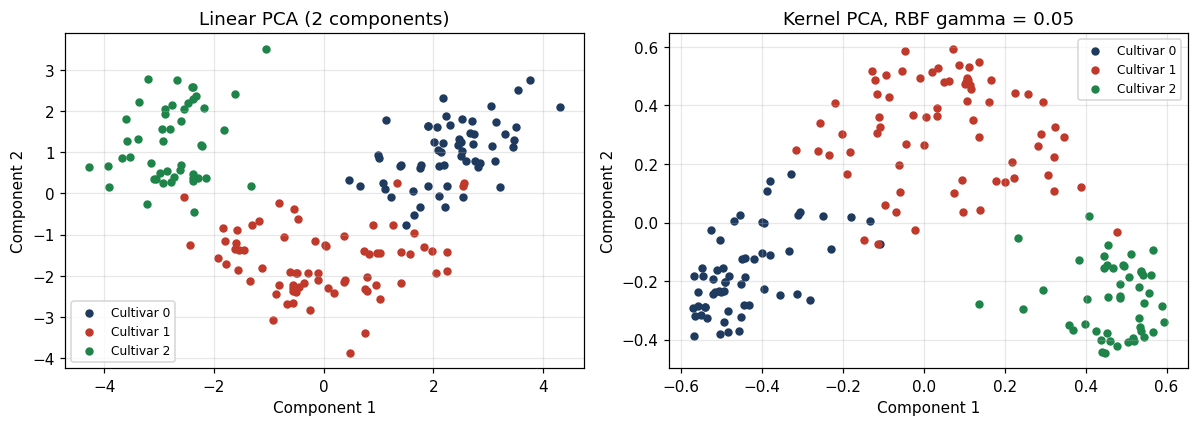

In [16]:
gbest = kpca.ARI_vs_cultivar.idxmax()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in range(3):
    ax[0].scatter(Z[y_true.values == c, 0], Z[y_true.values == c, 1], s=20, color=cols[c], label=f"Cultivar {c}")
    ax[1].scatter(kp[gbest][y_true.values == c, 0], kp[gbest][y_true.values == c, 1], s=20, color=cols[c], label=f"Cultivar {c}")
ax[0].set_title("Linear PCA (2 components)"); ax[1].set_title(f"Kernel PCA, RBF gamma = {gbest}")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3); a.set_xlabel("Component 1"); a.set_ylabel("Component 2")
plt.tight_layout()

## 8. Comparison of all methods

In [17]:
Kbest = kk.ARI_vs_cultivar.idxmax()
lab_kkm = kernel_kmeans(rbf_kernel(Xs, gamma=Kbest), 3, seed=1)
lab_pca2 = KMeans(3, n_init=20, random_state=RS).fit_predict(PCA(2).fit_transform(Xs))
lab_kpca = KMeans(3, n_init=20, random_state=RS).fit_predict(kp[gbest])
comp = []
for name, lab, space in (("K-Means (13 scaled features)", labels_km, Xs), ("K-Means on raw (unscaled) data", raw.labels_, X.values),
                         ("PCA (2 comp.) + K-Means", lab_pca2, PCA(2).fit_transform(Xs)), (f"Kernel PCA (gamma={gbest}) + K-Means", lab_kpca, kp[gbest]),
                         (f"Kernel K-Means (gamma={Kbest})", lab_kkm, Xs)):
    comp.append([name, round(silhouette_score(space, lab), 3), round(adjusted_rand_score(y_true, lab), 3), round(normalized_mutual_info_score(y_true, lab), 3)])
comparison = pd.DataFrame(comp, columns=["method", "silhouette (own space)", "ARI vs cultivar", "NMI vs cultivar"]).set_index("method")
comparison

                                   silhouette (own space)  ARI vs cultivar  NMI vs cultivar
method                                                                                     
K-Means (13 scaled features)                        0.285            0.897            0.876
K-Means on raw (unscaled) data                      0.571            0.371            0.429
PCA (2 comp.) + K-Means                             0.561            0.895            0.882
Kernel PCA (gamma=0.05) + K-Means                   0.617            0.931            0.909
Kernel K-Means (gamma=0.1)                          0.282            0.949            0.928

In [18]:
SUMMARY = dict(n=int(X.shape[0]), p=int(X.shape[1]), evr=[round(float(v), 4) for v in evr[:6]], cum=[round(float(v), 4) for v in cum[:6]],
               n80=int(np.argmax(cum >= .8) + 1), n90=int(np.argmax(cum >= .9) + 1), sizes=np.bincount(labels_km).tolist(),
               ari_raw=round(adjusted_rand_score(y_true, raw.labels_), 3), ari_scaled=round(adjusted_rand_score(y_true, scaled.labels_), 3),
               stab_min=round(min(aris), 3), stab_mean=round(float(np.mean(aris)), 3),
               pc1=load.PC1.sort_values(key=abs, ascending=False).head(4).round(2).to_dict(), pc2=load.PC2.sort_values(key=abs, ascending=False).head(4).round(2).to_dict(),
               gbest=float(gbest), Kbest=float(Kbest), best_sil_k=int(sel.silhouette.idxmax()))
print("stored")

stored


## 9. Interpretation, results and conclusions
* **Choice of k:** the elbow curve bends at k = 3 and the silhouette score is highest at k = 3, which agrees with the three known cultivars. K-Means with k = 3 gave clusters of sizes [65, 51, 62].
* **Scaling is essential:** on the raw data K-Means reaches an ARI of only 0.371 because *proline* (values up to about 1700) dominates the Euclidean distance; after standardisation the ARI is 0.897.
* **Stability:** 20 single random starts agree well with the best solution (mean ARI 0.97, minimum 0.882): a few runs end in a slightly different local optimum, which is why several initialisations (`n_init`) are used and the best one kept.
* **PCA:** the first two components explain 55% of the variance, and 5 components are enough for 80% (8 for 90%) — the 13 chemical measurements are highly redundant. PC1 is dominated by flavanoids, total phenols, OD280/OD315 and proanthocyanins (a **phenolic-content** axis); PC2 is dominated by colour intensity, alcohol and proline (an **intensity / strength** axis). In the PC1–PC2 plane the three cultivars form three well separated groups, so a 2-D picture preserves the structure.
* **Kernel methods:** Kernel PCA + K-Means (ARI 0.931) and Kernel K-Means (ARI 0.949) agree slightly better with the cultivars than plain K-Means (ARI 0.897). **This gain must be read with care:** the RBF width `gamma` was chosen by looking at the hidden cultivar labels (optimistic), the best value lies at the upper edge of the tested range, and the improvement is only a few percentage points, i.e. a few wines. In a real unsupervised problem `gamma` would have to be chosen with an internal criterion. Because the scaled data are already almost linearly separable, kernels give at most a **small advantage** here.
* **Comparing methods:** silhouette values computed in *different* spaces are **not comparable** (for example the 0.571 for unscaled K-Means only reflects that one feature, proline, dominates the distances); the agreement with the true cultivars (ARI/NMI) is the fairer comparison in this teaching example.
* **Conclusion:** the unsupervised methods **recovered the three cultivars without labels** (ARI about 0.9 for all properly scaled methods), PCA gave an interpretable low-dimensional view, and the comparison table in Section 8 summarises all methods. 
* **Limitations:** a small data set with clean, well separated groups; ARI/NMI use the hidden labels, which are normally unavailable in real unsupervised problems (internal indices such as the silhouette must then be used).